Train: 28417
Validation: 4060
Test: 8120
Class Weights: {0: np.float64(0.865448454393178), 1: np.float64(0.7038440580571655), 2: np.float64(2.3598239495100484)}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 89s 361ms/step - accuracy: 0.6328 - loss: 0.7369 - val_accuracy: 0.8968 - val_loss: 0.3010 - learning_rate: 0.0010
Epoch 2/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 78s 349ms/step - accuracy: 0.9076 - loss: 0.2403 - val_accuracy: 0.9062 - val_loss: 0.2744 - learning_rate: 0.0010
Epoch 3/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 78s 350ms/step - accuracy: 0.9356 - loss: 0.1606 - val_accuracy: 0.9057 - val_loss: 0.2739 - learning_rate: 0.0010
Epoch 4/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 77s 346ms/step - accuracy: 0.9573 - loss: 0.1108 - val_accuracy: 0.9025 - val_loss: 0.3322 - learning_rate: 0.0010
Epoch 5/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 78s 351ms/step - accuracy: 0.9649 - loss: 0.0852 - val_accuracy: 0.9012 - val_loss: 0.3892 - learning_rate: 0.0010
Epoch 6/25
223/223 ━━━━━━━━━━━━━━━━━━━━ 78s 349ms/step - accuracy: 0.9742 - loss: 0.0636 - val_accuracy: 0.9062 - val_loss: 0.3802 - learning_rate: 5.0000e-04
889/889 ━━━━━━━━━━━━━━━━━━━━ 33s 36ms/step
127/127 ━━━━━━━━━━━━━━━

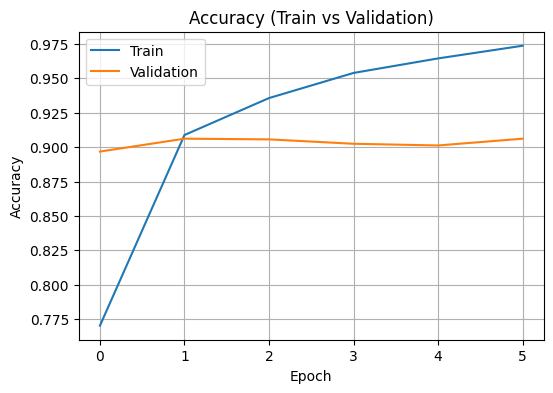

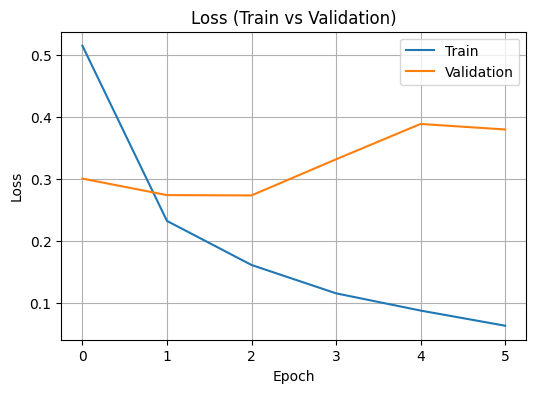

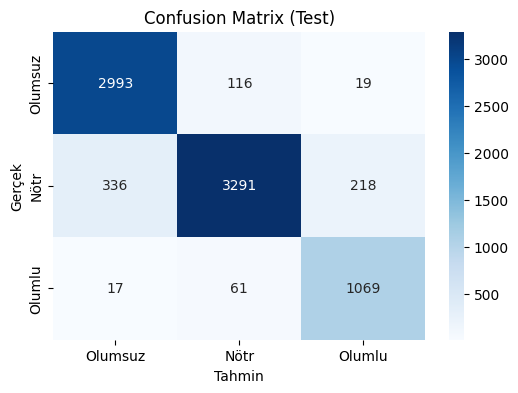

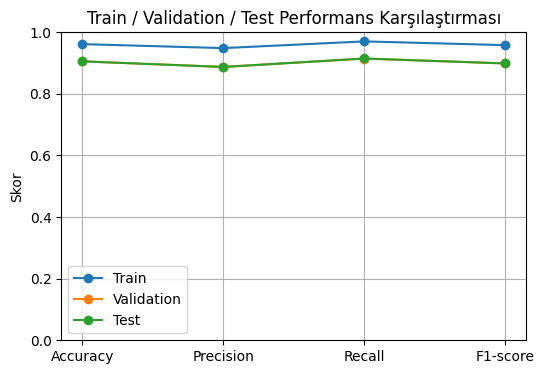

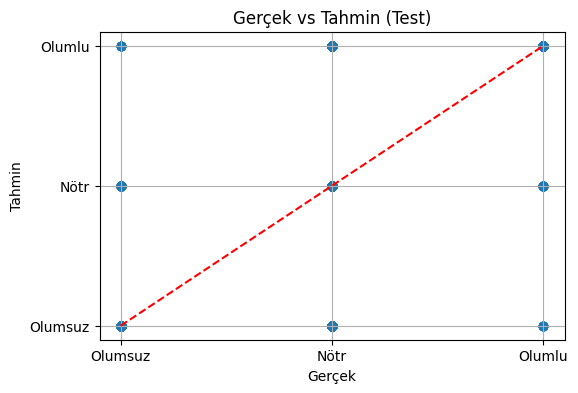

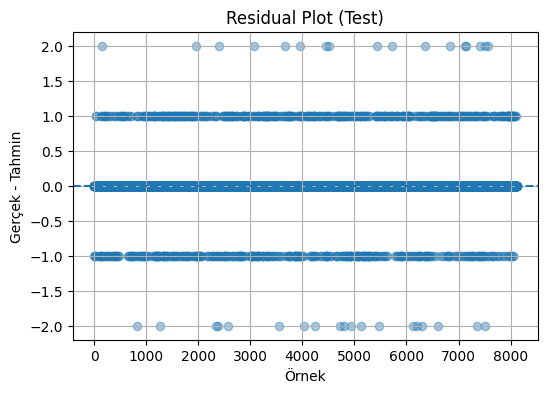

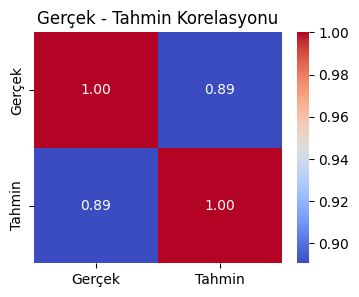

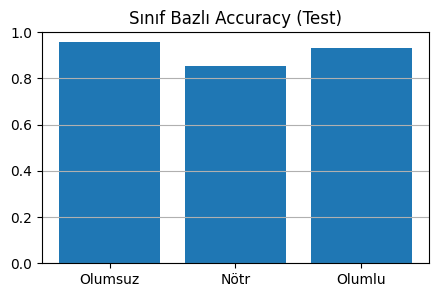

254/254 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step


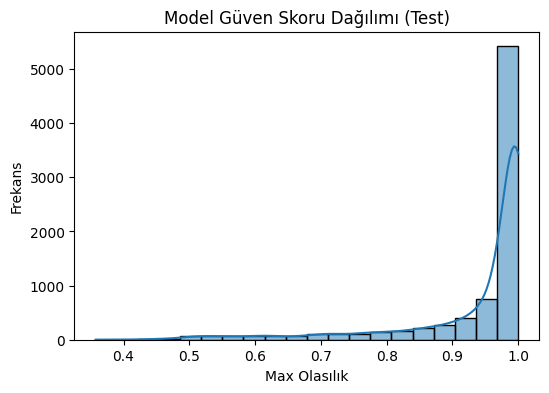

In [1]:
# ===================================================
# 0) KÜTÜPHANELER
# ===================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical


# ===================================================
# 1) VERİ YÜKLEME (SADECE CSV)
# ===================================================
df = pd.read_csv("Turkish-Review-Sentiment-Data.csv")
df.columns = [c.lower() for c in df.columns]

text_col = "review"
label_col = "sentiment"


# ===================================================
# 2) LABEL MAPPING
# ===================================================
label_map = {
    "olumsuz": 0, "negatif": 0,
    "nötr": 1, "notr": 1, "neutral": 1,
    "olumlu": 2, "pozitif": 2, "positive": 2
}

df[label_col] = (
    df[label_col]
    .astype(str)
    .str.lower()
    .map(label_map)
    .fillna(1)
    .astype(int)
)


# ===================================================
# 3) METİN TEMİZLEME
# ===================================================
def clean_text(t):
    if pd.isna(t):
        return ""
    return str(t).lower().replace("\n", " ").strip()

df[text_col] = df[text_col].apply(clean_text)


# ===================================================
# 4) TRAIN / VAL / TEST SPLIT (%70 / %10 / %20)
# ===================================================
X = df[text_col]
y = df[label_col]

# %70 Train, %30 (Val+Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# %10 Val, %20 Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=2/3, random_state=42, stratify=y_temp
)

print(f"Train: {len(X_train)}")
print(f"Validation: {len(X_val)}")
print(f"Test: {len(X_test)}")


# ===================================================
# 5) TOKENIZER + PADDING
# ===================================================
max_words = 20000
max_len = 80

tokenizer = Tokenizer(num_words=max_words, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

def tokenize_pad(texts):
    seq = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seq, maxlen=max_len, padding="post")

X_train_seq = tokenize_pad(X_train)
X_val_seq   = tokenize_pad(X_val)
X_test_seq  = tokenize_pad(X_test)

y_train_cat = to_categorical(y_train, 3)
y_val_cat   = to_categorical(y_val, 3)
y_test_cat  = to_categorical(y_test, 3)


# ===================================================
# 6) CLASS WEIGHT
# ===================================================
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))
print("Class Weights:", class_weight_dict)


# ===================================================
# 7) BiLSTM MODEL
# ===================================================
model = Sequential([
    Embedding(input_dim=max_words, output_dim=128),
    Bidirectional(LSTM(64, dropout=0.4, recurrent_dropout=0.4)),
    Dense(64, activation="relu"),
    Dropout(0.5),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


# ===================================================
# 8) CALLBACKS
# ===================================================
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", patience=2, factor=0.5, min_lr=1e-5)


# ===================================================
# 9) EĞİTİM
# ===================================================
history = model.fit(
    X_train_seq, y_train_cat,
    validation_data=(X_val_seq, y_val_cat),
    epochs=25,
    batch_size=128,
    class_weight=class_weight_dict,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)


# ===================================================
# 10) METRİK FONKSİYONU
# ===================================================
def calc_metrics(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro"
    )
    return acc, p, r, f1


# ===================================================
# 11) TRAIN / VAL / TEST METRİK TABLOSU
# ===================================================
train_pred = model.predict(X_train_seq).argmax(axis=1)
val_pred   = model.predict(X_val_seq).argmax(axis=1)
test_pred  = model.predict(X_test_seq).argmax(axis=1)

metrics_df = pd.DataFrame({
    "Accuracy": [
        calc_metrics(y_train, train_pred)[0],
        calc_metrics(y_val, val_pred)[0],
        calc_metrics(y_test, test_pred)[0]
    ],
    "Precision": [
        calc_metrics(y_train, train_pred)[1],
        calc_metrics(y_val, val_pred)[1],
        calc_metrics(y_test, test_pred)[1]
    ],
    "Recall": [
        calc_metrics(y_train, train_pred)[2],
        calc_metrics(y_val, val_pred)[2],
        calc_metrics(y_test, test_pred)[2]
    ],
    "F1-score": [
        calc_metrics(y_train, train_pred)[3],
        calc_metrics(y_val, val_pred)[3],
        calc_metrics(y_test, test_pred)[3]
    ]
}, index=["Train", "Validation", "Test"])

print("\n=== BİLSTM PERFORMANS TABLOSU ===")
print(metrics_df)


# ===================================================
# =================== GRAFİKLER =====================
# ===================================================

# 1) Accuracy
plt.figure(figsize=(6,4))
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Accuracy (Train vs Validation)")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.grid(True)
plt.show()


# 2) Loss
plt.figure(figsize=(6,4))
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Loss (Train vs Validation)")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.grid(True)
plt.show()


# 3) Confusion Matrix (Test)
cm_test = confusion_matrix(y_test, test_pred)
plt.figure(figsize=(6,4))
sns.heatmap(
    cm_test, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Olumsuz", "Nötr", "Olumlu"],
    yticklabels=["Olumsuz", "Nötr", "Olumlu"]
)
plt.title("Confusion Matrix (Test)")
plt.xlabel("Tahmin")
plt.ylabel("Gerçek")
plt.show()


# 4) Train vs Val vs Test Karşılaştırması
plt.figure(figsize=(6,4))
for idx in metrics_df.index:
    plt.plot(metrics_df.columns, metrics_df.loc[idx], marker="o", label=idx)

plt.title("Train / Validation / Test Performans Karşılaştırması")
plt.ylabel("Skor")
plt.ylim(0,1)
plt.legend()
plt.grid(True)
plt.show()


# 5) Gerçek vs Tahmin (Scatter)
plt.figure(figsize=(6,4))
plt.scatter(y_test, test_pred, alpha=0.4)
plt.plot([0,1,2], [0,1,2], "r--")
plt.xticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.yticks([0,1,2], ["Olumsuz","Nötr","Olumlu"])
plt.xlabel("Gerçek")
plt.ylabel("Tahmin")
plt.title("Gerçek vs Tahmin (Test)")
plt.grid(True)
plt.show()


# 6) Residual Plot
residuals = y_test.values - test_pred
plt.figure(figsize=(6,4))
plt.scatter(range(len(residuals)), residuals, alpha=0.4)
plt.axhline(0, linestyle="--")
plt.title("Residual Plot (Test)")
plt.xlabel("Örnek")
plt.ylabel("Gerçek - Tahmin")
plt.grid(True)
plt.show()


# 7) Korelasyon Matrisi
corr_df = pd.DataFrame({"Gerçek": y_test, "Tahmin": test_pred})
plt.figure(figsize=(4,3))
sns.heatmap(corr_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Gerçek - Tahmin Korelasyonu")
plt.show()


# 8) Sınıf Bazlı Accuracy
class_names = ["Olumsuz", "Nötr", "Olumlu"]
class_acc = []

for cls in [0,1,2]:
    idx = np.where(y_test.values == cls)
    acc = accuracy_score(y_test.values[idx], test_pred[idx])
    class_acc.append(acc)

plt.figure(figsize=(5,3))
plt.bar(class_names, class_acc)
plt.title("Sınıf Bazlı Accuracy (Test)")
plt.ylim(0,1)
plt.grid(axis="y")
plt.show()


# 9) Güven Skoru Dağılımı
test_probs = model.predict(X_test_seq)
confidence = test_probs.max(axis=1)

plt.figure(figsize=(6,4))
sns.histplot(confidence, bins=20, kde=True)
plt.title("Model Güven Skoru Dağılımı (Test)")
plt.xlabel("Max Olasılık")
plt.ylabel("Frekans")
plt.show()
